# A museum's shopping history — MoMA's collection through `cdp-kernel`

Every museum is a record of buying decisions. The Museum of Modern Art publishes
its **entire cataloged collection** — 160k+ works and their artists — as open data,
including the date each work was *acquired*. That turns the museum itself into a
dataset: what was bought when, how long after it was made, from whom, and in what.

This notebook reads like a visit: we load and clean the data with
[Polars](https://github.com/pola-rs/nodejs-polars), chart it with
[Observable Plot](https://observablehq.com/plot), build a small interactive
widget on cdp-kernel's comm protocol, and end with a one-work-per-decade tour
rendered as museum wall labels.

It runs on **cdp-kernel** with a **Node** target: the kernel host speaks the
Jupyter wire protocol while every cell executes over CDP in a separate Node
process — TypeScript and TSX are transformed on the way in.

## Sources and inspiration

The analysis approach here is **inspired by Trevor Manz's post [_Exploring Art
with TypeScript, Jupyter, Polars, and Observable Plot_](https://deno.com/blog/exploring-art-with-typescript-and-jupyter)**
([notebook source](https://github.com/manzt/deno-jupyter-blog)), which explores
the National Gallery of Art's open data under Deno's Jupyter kernel. The structure
of that piece — tidy data, static plots, an anywidget-style table, a custom SSR
component — is a lovely template for what a notebook-driven runtime should be
able to do, so this notebook deliberately exercises the same breadth.

All code and prose here are original, the dataset is different, and the questions
asked are different (the inspiration focuses on *when art was made*; we mostly ask
*when the museum acquired it*). No code or text is copied from the original.

**Data** — [MuseumofModernArt/collection](https://github.com/MuseumofModernArt/collection)
on GitHub, released into the public domain (**CC0**). Per that repository, images
are *not* part of the dataset, and much of the metadata is "as is" research data,
not curator-approved. Links in this notebook go to the museum's own collection
pages.

Specifiers below pin what needs pinning (react and react-dom ranges must agree —
React enforces version parity between the pair).

## Load

In [1]:
import * as pl from "npm:nodejs-polars@0.18.0";

const baseUrl = "https://github.com/MuseumofModernArt/collection/raw/refs/heads/main/";

// MoMA ships CSVs with a UTF-8 BOM; strip it so the first column name is clean.
const stripBom = (s: string) => s.replace(/^\uFEFF/, "");

let artists: pl.DataFrame = pl.readCSV(
  stripBom(await (await fetch(baseUrl + "Artists.csv")).text()),
  { quoteChar: '"' },
)
  .select(
    pl.col("ConstituentID").alias("artistId"),
    pl.col("DisplayName").alias("artist"),
    pl.col("Nationality").alias("nationality"),
    pl.col("Gender").str.toLowerCase().alias("gender"),
  );

artists.head();

artistId,artist,nationality,gender
1,Robert Arneson,American,male
2,Doroteo Arnaiz,Spanish,male
3,Bill Arnold,American,male
4,Charles Arnoldi,American,male
5,Per Arnoldi,Danish,male


In [2]:
let works: pl.DataFrame = pl.readCSV(
  stripBom(await (await fetch(baseUrl + "Artworks.csv")).text()),
  { quoteChar: '"' },
)
  .select(
    pl.col("ObjectID"),
    pl.col("Title"),
    pl.col("Artist"),
    pl.col("ConstituentID"),
    pl.col("Date").alias("dateText"),
    pl.col("Medium"),
    pl.col("Classification"),
    pl.col("Department"),
    pl.col("DateAcquired"),
    pl.col("CreditLine"),
    pl.col("AccessionNumber"),
    pl.col("URL"),
    pl.col("Height (cm)").alias("heightCm"),
    pl.col("Width (cm)").alias("widthCm"),
    pl.col("Duration (sec.)").alias("durationSec"),
  );

`${works.shape.height.toLocaleString()} works, ${artists.shape.height.toLocaleString()} artists`

'160,682 works, 15,934 artists'

## Clean

Two messy columns do most of the damage. `DateAcquired` is a clean ISO date when
present; the work's `Date` is free text (`c. 1910`, `1935-42`, `Published 1929`…),
so we take the first plausible four-digit year as an approximate work year.

In [3]:
works = works.withColumns(
  pl.col("DateAcquired").str.slice(0, 4).cast(pl.Int32, false).alias("acquiredYear"),
  pl.col("dateText").str.extract("(1[5-9][0-9][0-9]|20[0-9][0-9])", 1).cast(pl.Int32, false).alias("workYear"),
);

const knownAcquired = works.filter(pl.col("acquiredYear").isNotNull()).shape.height;
const knownWorkYear = works.filter(pl.col("workYear").isNotNull()).shape.height;
`acquisition year known for ${knownAcquired.toLocaleString()} / ${works.shape.height.toLocaleString()} works; approximate work year for ${knownWorkYear.toLocaleString()}`

'acquisition year known for 155,220 / 160,682 works; approximate work year for 156,257'

In [4]:
// Collaborations: some works list several constituent IDs. The first one is the
// primary artist (the Artist string lists names in the same order).
const collaborations = works.filter(pl.col("ConstituentID").str.contains(",")).shape.height;

works = works.withColumns(
  pl.col("ConstituentID").str.extract("([0-9]+)", 1).cast(pl.Int64, false).alias("primaryArtistId"),
  pl.col("acquiredYear").sub(pl.col("acquiredYear").rem(10)).alias("acquiredDecade"),
);

works = works.join(artists, {
  leftOn: "primaryArtistId",
  rightOn: "artistId",
  how: "left",
});

`join done — ${collaborations.toLocaleString()} works credit multiple artists; primary artist joined for `
  + `${works.filter(pl.col("artist").isNotNull()).shape.height.toLocaleString()} works`

'join done — 8,111 works credit multiple artists; primary artist joined for 159,425 works'

## When the museum buys


In [5]:
import * as Plot from "npm:@observablehq/plot";
import { parseHTML } from "npm:linkedom@0.18.9";

// Observable Plot wants a DOM; on a Node target we hand it linkedom
// (the same trick most SSR renderers use).
const document = parseHTML("<html></html>").document;

const acquisitions = works
  .filter(pl.col("acquiredYear").isNotNull())
  .withColumns(pl.col("Department").fillNull("Unspecified"))
  .toRecords();

Plot.plot({
  width: 940,
  height: 300,
  y: { grid: true, label: "works acquired" },
  x: { type: "time", domain: [new Date(1925, 0, 1), new Date(2027, 0, 1)] },
  marks: [
    Plot.rectY(
      acquisitions,
      Plot.binX(
        { y: "count", filter: null },
        {
          x: (d) => new Date(d.acquiredYear, 0, 1),
          thresholds: 102,
          fill: "Department",
          fillOpacity: 0.9,
        },
      ),
    ),
  ],
  color: { legend: true },
  document,
});

Architecture & Design Drawings & Prints Film Fluxus Collection Media and Performance Painting & Sculpture Photography 0 2,000 4,000 6,000 8,000 10,000 12,000 14,000 16,000 18,000 20,000 ↑ works acquired 1930 1940 1950 1960 1970 1980 1990 2000 2010 2020

In [6]:
const busiest = works
  .filter(pl.col("acquiredYear").isNotNull())
  .groupBy("acquiredYear").len()
  .sort("acquiredYear_count", true)
  .head(10);

jupyter.md`## The ten busiest acquisition years

${busiest.toRecords()
  .map((r) => `| ${r.acquiredYear} | ${Number(r.acquiredYear_count).toLocaleString()} |`)
  .join("\n")}

(year | works acquired)`

## The ten busiest acquisition years

| 1968 | 20,528 |
| 1964 | 12,997 |
| 2008 | 7,443 |
| 2001 | 4,169 |
| 2005 | 4,062 |
| 2015 | 3,882 |
| 1974 | 3,656 |
| 2013 | 3,127 |
| 2012 | 2,962 |
| 2014 | 2,866 |

(year | works acquired)

In [7]:
// What did the museum buy in its biggest year?
const busiestYear = busiest.toRecords()[0].acquiredYear as number;

const biggestYear = works
  .filter(pl.col("acquiredYear").eq(pl.lit(busiestYear)))
  .groupBy("Classification").len()
  .sort("Classification_count", true)
  .head(6);

biggestYear

Classification,Classification_count
Mies van der Rohe Archive,13622
Photograph,5457
Print,512
Illustrated Book,457
Drawing,253
Design,171


In [8]:
const samples = works
  .filter(pl.col("acquiredYear").eq(pl.lit(busiestYear)))
  .sort("Title").head(12)
  .select("Title", "Artist", "Classification", "CreditLine");

samples

Title,Artist,Classification,CreditLine
"""Johnny""",Edward Weston,Photograph,Gift of David H. McAlpin
"""M'Amenez-y""",Francis Picabia,Painting,Helena Rubinstein Fund
"""The Museum of Modern Art Packed Project""",Christo,Drawing,Gift of D. and J. de Menil
"""raum technik system rts"" Shelving System","Hans Staeger, Manfred Malzacher",Design,Gift of Beylerian Ltd.
(Untitled),Josef Raynefeld,Drawing,Gift of Jacques Lassaigne
(Untitled),Josef Raynefeld,Drawing,Gift of Jacques Lassaigne
"1 rue Brisemiche, Vieille Maison",Eugène Atget,Photograph,"Abbott-Levy Collection. Acquired through the generosity of Shirley C. Burden, and Family of Man Fund"
1/2 Brown Curved Area Series V,Robert Mangold,Print,John B. Turner Fund
1/2 Gray Curved Area Series X,Robert Mangold,Print,John B. Turner Fund
1/2 Manila Curved Area Series W,Robert Mangold,Print,John B. Turner Fund


## The 1968 spike, explained

Nearly two-thirds of the museum's biggest year — **13,622 of 20,528 works** — are
classified **Mies van der Rohe Archive**. That's not a buying spree; it's a life's work
arriving. Mies van der Rohe wanted his entire öuvre to go to MoMA, and the museum's
trustees established the archive in 1968; the architect died in 1969. What the histogram
records as a single-year spike is mostly **one architect handing over ~19,000 drawings
and prints** — about a thousand of them by his longtime collaborator [Lilly
Reich](https://en.wikipedia.org/wiki/Ludwig_Mies_van_der_Rohe#Archives). The runner-up
year, 1964, doesn't have one clean story like that — it's a broad elevation across
photographs and prints.

The interactive scrubber below lets you slice this yourself.

## How long does art wait?

The lag between a work's creation and its acquisition is a quiet census of taste:
how quickly a museum decides a medium matters.

Classification,n,medianLag
Notebook,2000,66
Periodical,768,54.5
Photograph,31446,41
Multiple,1102,36


Classification,n,medianLag
Video,2361,15
Installation,850,7
Print,32207,6


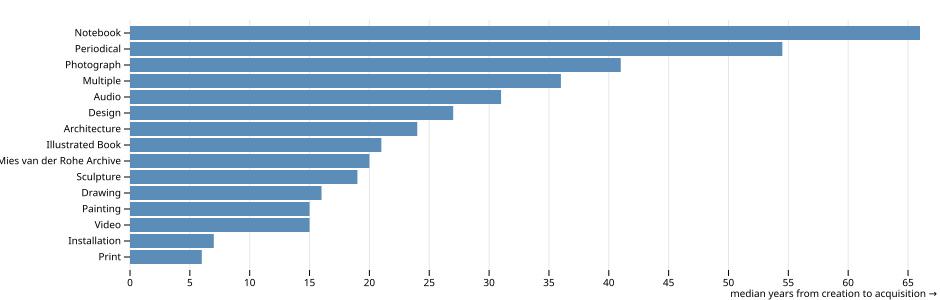

In [9]:
const lagByClass = works
  .filter(pl.col("acquiredYear").isNotNull())
  .withColumns(pl.col("acquiredYear").minus(pl.col("workYear")).alias("lagYears"))
  .filter(pl.col("lagYears").gtEq(pl.lit(0)).and(pl.col("lagYears").lt(pl.lit(100))))
  .groupBy("Classification")
  .agg(pl.col("lagYears").count().alias("n"), pl.col("lagYears").median().alias("medianLag"))
  .filter(pl.col("n").gt(pl.lit(500)))
  .sort("medianLag", true);

// the extremes of the distribution, as numbers:
await jupyter.display(lagByClass.head(4));
await jupyter.display(lagByClass.tail(3));

Plot.plot({
  width: 940,
  marginLeft: 130,
  height: 300,
  x: { grid: true, label: "median years from creation to acquisition" },
  y: { label: null },
  marks: [
    Plot.barX(lagByClass.toRecords(), {
      x: "medianLag",
      y: "Classification",
      sort: { y: "-x" },
      fill: "#5b8db8",
    }),
  ],
  document,
});

## Who gets collected

MoMA's artist records include a gender field (as recorded by museum staff —
imperfect and historical, but the museum publishes it and its gaps are themselves
part of the story). The share of acquisitions credited to women, per acquisition
year, is a slow-moving number worth staring at.

acquiredYear,femaleShare,n
1933,0,93
1934,0.016260162601626018,246


acquiredYear,femaleShare,n
2025,0.37948717948717947,780
2026,0.38415841584158417,505


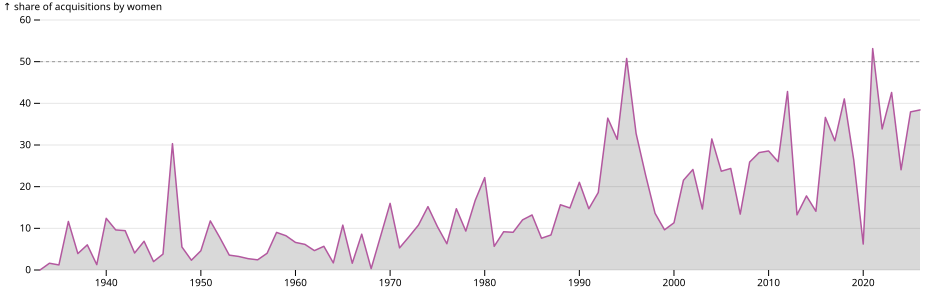

In [10]:
const genderShare = works
  .filter(pl.col("acquiredYear").isNotNull())
  .filter(pl.col("gender").eq(pl.lit("female")).or(pl.col("gender").eq(pl.lit("male"))))
  .withColumns(pl.col("gender").eq(pl.lit("female")).cast(pl.Int32).alias("isFemale"))
  .groupBy("acquiredYear")
  .agg(pl.col("isFemale").mean().alias("femaleShare"), pl.len().alias("n"))
  .filter(pl.col("n").gt(pl.lit(20)))
  .sort("acquiredYear");

await jupyter.display(genderShare.head(2));
await jupyter.display(genderShare.tail(2));

Plot.plot({
  width: 940,
  height: 300,
  y: { grid: true, domain: [0, 60], percent: true, label: "share of acquisitions by women" },
  x: { type: "time", label: null },
  marks: [
    Plot.areaY(genderShare.toRecords(), {
      x: (d) => new Date(d.acquiredYear, 0, 1),
      y: "femaleShare",
      fillOpacity: 0.15,
    }),
    Plot.lineY(genderShare.toRecords(), {
      x: (d) => new Date(d.acquiredYear, 0, 1),
      y: "femaleShare",
      stroke: "#b3589f",
    }),
    Plot.ruleY([0.5], { stroke: "#999", strokeDasharray: "3,3" }),
  ],
  document,
});

## The chemical century

Photography arrived as chemistry and left as software. The `Medium` column lets us
watch the processes rise and fall — silver gelatin giving way to chromogenic
prints, then inkjet.

In [11]:
const photoWorks = works
  .filter(pl.col("workYear").isNotNull())
  .withColumns(
    pl.when(pl.col("Medium").str.contains("(?i)gelatin silver"))
      .then(pl.lit("gelatin silver")).otherwise(pl.lit(null)).alias("process"),
  )
  .withColumns(
    pl.when(pl.col("Medium").str.contains("(?i)chromogenic"))
      .then(pl.lit("chromogenic")).otherwise(pl.col("process")).alias("process"),
  )
.withColumns(
    pl.when(pl.col("Medium").str.contains("(?i)inkjet|pigment print"))
      .then(pl.lit("digital inkjet")).otherwise(pl.col("process")).alias("process"),
  )
  .filter(pl.col("process").isNotNull());

await jupyter.display(
  photoWorks.groupBy("process").agg(
    pl.col("workYear").min().alias("firstWork"),
    pl.col("workYear").max().alias("lastWork"),
    pl.col("workYear").count().alias("works")));

Plot.plot({
  width: 940,
  height: 300,
  y: { grid: true, label: "works (binned)" },
  x: { type: "time", domain: [new Date(1890, 0, 1), new Date(2025, 0, 1)] },
  color: { legend: true },
  marks: [
    Plot.rectY(
      photoWorks.toRecords(),
      Plot.binX(
        { y: "count", filter: null },
        {
          x: (d) => new Date(d.workYear, 0, 1),
          thresholds: 68,
          fill: "process",
          fillOpacity: 0.85,
        },
      ),
    ),
  ],
  document,
});

process,firstWork,lastWork,works
gelatin silver,1838,2025,21942
chromogenic,1900,2025,2684
digital inkjet,1853,2025,1643


chromogenic digital inkjet gelatin silver 0 200 400 600 800 1,000 1,200 1,400 ↑ works (binned) 1890 1900 1910 1920 1930 1940 1950 1960 1970 1980 1990 2000 2010 2020

## The longest works in the collection

MoMA collects time-based media, and the dataset records runtimes. A nice excuse
to pull in a package from JSR — `@std/fmt`'s duration formatter.

In [12]:
import { format as formatDuration } from "jsr:@std/fmt@1.0.10/duration";

const longest = works
  .filter(pl.col("durationSec").isNotNull())
  .sort("durationSec", true)
  .head(5)
  .withColumns(pl.col("durationSec").cast(pl.Float64))
  .select("Title", "Artist", "durationSec", "URL")
  .toRecords();

const rows = longest.map((w) =>
  `| ${(w.Title as string).slice(0, 60)} | ${w.Artist ?? "Unknown"} | ${formatDuration((w.durationSec as number) * 1000, { ignoreZero: true })} |`)
  .join("\n");

jupyter.md`## The five longest works in the collection

| Work | Artist | Runtime |
| --- | --- | --- |
${rows}`

## The five longest works in the collection

| Work | Artist | Runtime |
| --- | --- | --- |
| Interrupted Line | VALIE EXPORT | 16m 38s |
| Cuts: Elements of Observation | VALIE EXPORT | 16m 34s |
| Naked Doom | Edward Rankus | 16m 31s |
| Delta: A Piece | VALIE EXPORT | 16m 31s |
| Delta. A Piece | VALIE EXPORT | 16m 27s |

## An interactive acquisition scrubber

Widgets are where cdp-kernel differs most from `deno jupyter`: the kernel side
speaks the ipywidgets model protocol directly through `jupyter.widget`. The
`esm` string below is the frontend — plain vanilla JS, no CDN, no bundler —
and it talks back: dragging the sliders updates the model, the kernel listens
for the change and pushes a fresh summary down.

In [13]:
const yearCounts = works
  .filter(pl.col("acquiredYear").isNotNull())
  .groupBy("acquiredYear").len()
  .sort("acquiredYear")
  .toRecords()
  .map((r) => [r.acquiredYear as number, Number(r.acquiredYear_count)] as const);

const totalAcquired = yearCounts.reduce((sum, [, n]) => sum + n, 0);

const summarize = (start: number, end: number) => {
  const inRange = yearCounts.filter(([y]) => y >= start && y <= end);
  const count = inRange.reduce((s, [, n]) => s + n, 0);
  return `${count.toLocaleString()} works (${(100 * count / totalAcquired).toFixed(1)}% of the collection) entered MoMA between ${start} and ${end}`;
};

const scrubber = jupyter.widget({
  state: {
    start: 1929,
    end: 2026,
    counts: yearCounts,
    summary: summarize(1929, 2026),
  },
  esm: `
export default ({ model, el }) => {
  el.style.font = "12px system-ui, sans-serif";
  const canvas = document.createElement("canvas");
  const draw = () => {
    const counts = model.get("counts") || [];
    const start = model.get("start"), end = model.get("end");
    const W = 640, H = 120, max = Math.max(...counts.map(([, n]) => n), 1);
    canvas.width = W * 2; canvas.height = H * 2;
    canvas.style.width = W + "px"; canvas.style.height = H + "px";
    const ctx = canvas.getContext("2d");
    ctx.scale(2, 2);
    const y0 = counts[0] ? counts[0][0] : 1929, y1 = counts.length ? counts[counts.length - 1][0] : 2026;
    for (const [year, n] of counts) {
      const x = ((year - y0) / (y1 - y0)) * W;
      const h = (n / max) * (H - 24);
      ctx.fillStyle = year >= start && year <= end ? "#5b8db8" : "#d8d8d8";
      ctx.fillRect(x, H - h, Math.max(1, W / (y1 - y0)), h);
    }
    ctx.fillStyle = "#555";
    ctx.fillText(y0, 2, H - 4); ctx.fillText(y1, W - 28, H - 4);
  };
  const row = document.createElement("div");
  row.style.display = "flex"; row.style.gap = "8px"; row.style.alignItems = "center";
  const mk = (key) => {
    const s = document.createElement("input");
    s.type = "range"; s.min = 1929; s.max = 2026;
    s.oninput = () => model.set({ [key]: +s.value });
    s.value = model.get(key);
    model.on("change:" + key, () => { s.value = model.get(key); });
    return s;
  };
  const start = mk("start"), end = mk("end");
  const label = document.createElement("span");
  const sync = () => {
    label.textContent = model.get("start") + " \u2013 " + model.get("end");
    draw();
  };
  const summary = document.createElement("p");
  summary.style.minHeight = "1.2em";
  model.on("change:summary", () => { summary.textContent = model.get("summary"); });
  summary.textContent = model.get("summary");
  el.append(canvas, row, summary);
  row.append(start, label, end);
  model.on("change:start", sync);
  model.on("change:end", sync);
  sync();
};
  `,
});

// The kernel half of the loop: frontend slider changes arrive as comm updates;
// we recompute and push the summary back.
for (const key of ["start", "end"]) {
  scrubber.on("change:" + key, (value: number) =>
    scrubber.set({ summary: summarize(scrubber.get("start"), scrubber.get("end")) }));
}

// exercise the round trip from the kernel side:
scrubber.set({ start: 1964, end: 1980 });
console.log(`after kernel-side set(): ${scrubber.get("summary")}`);

scrubber

after kernel-side set(): 56,552 works (36.4% of the collection) entered MoMA between 1964 and 1980


Widget(ac889f8b-b88d-4676-a448-3928c6fd718f)

## One work per decade — a wall-label tour

Custom display objects are just `[Symbol.for("Jupyter.display")]` methods, so any
renderer works. Here React SSRs a set of museum wall labels: the earliest-acquired
work from each decade of the museum's life, ten works you could walk past in
ninety years of buying.

In [14]:
import * as React from "npm:react@19";
import * as ReactDOMServer from "npm:react-dom@19/server";

const render = (node: React.ReactNode) => ({
  [Symbol.for("Jupyter.display")]() {
    return { "text/html": ReactDOMServer.renderToString(node) };
  },
});

const tour = works
  .filter(pl.col("acquiredYear").isNotNull().and(pl.col("URL").str.lengths().gt(pl.lit(0))))
  .sort("DateAcquired")
  .groupBy("acquiredDecade").first()
  .sort("acquiredDecade")
  .select("acquiredDecade", "Title", "artist", "dateText", "Medium", "CreditLine", "AccessionNumber", "URL");

function WallLabel(props: { work: Record<string, string> }) {
  const { work } = props;
  return (
    <div style={{
      border: "1px solid #ddd",
      borderRadius: "6px",
      padding: "14px 16px",
      background: "#faf9f7",
      fontFamily: "Georgia, serif",
    }}>
      <div style={{ fontSize: "11px", fontFamily: "system-ui, sans-serif", color: "#999", marginBottom: "6px" }}>
        acquired {(work.acquiredDecade ?? 0) as number}–{((work.acquiredDecade ?? 0) as number) + 9} · first purchase of the decade
      </div>
      <div style={{ fontStyle: "italic", fontSize: "15px", marginBottom: "4px" }}>
        {work.Title}
      </div>
      <div>{work.artist ?? "Unknown artist"}, {work.dateText}</div>
      <div style={{ color: "#555", fontSize: "12px", marginTop: "4px" }}>{work.Medium}</div>
      <div style={{ color: "#777", fontSize: "11px", marginTop: "6px" }}>
        {work.CreditLine}. {work.AccessionNumber} · {" "}
        <a href={work.URL} style={{ color: "#5b8db8" }}>moma.org</a>
      </div>
    </div>
  );
}

render((
  <div style={{ display: "grid", gridTemplateColumns: "repeat(auto-fill, minmax(280px, 1fr))", gap: "10px", maxWidth: 940 }}>
    {tour.toRecords().map((work) => (
      <WallLabel key={String(work.AccessionNumber)} work={work} />
    ))}
  </div>
));

acquired <!-- -->1920<!-- -->–<!-- -->1929<!-- --> · first purchase of the decade Anna Peter George Grosz<!-- -->, <!-- -->1926–27 Pencil on paper Gift of Paul J. Sachs<!-- -->. <!-- -->4.1929<!-- --> · <!-- --> moma.org acquired <!-- -->1930<!-- -->–<!-- -->1939<!-- --> · first purchase of the decade Railroad Gantry Charles Burchfield<!-- -->, <!-- -->1920 Gouache on paper Given anonymously<!-- -->. <!-- -->2.1930<!-- --> · <!-- --> moma.org acquired <!-- -->1940<!-- -->–<!-- -->1949<!-- --> · first purchase of the decade Lend the Way They Fight E. M. Ashe<!-- -->, <!-- -->1918 Lithograph Gift of Abby Aldrich Rockefeller<!-- -->. <!-- -->1567.1940<!-- --> · <!-- --> moma.org acquired <!-- -->1950<!-- -->–<!-- -->1959<!-- --> · first purchase of the decade Pacific Landscape Ben Shahn<!-- -->, <!-- -->1945 Tempera on paper over composition board Gift of Philip L. Goodwin<!-- -->. <!-- -->1.1950<!-- --> · <!-- --> moma.org acquired <!-- -->1960<!-- -->–<!-- -->1969<!-- --> · first purchase of the decade Airplane Hangar, project R. Buckminster Fuller<!-- -->, <!-- -->1955 Wood and paint Gift of the architect<!-- -->. <!-- -->560.1960<!-- --> · <!-- --> moma.org acquired <!-- -->1970<!-- -->–<!-- -->1979<!-- --> · first purchase of the decade Les Terrasses, Villa Stein-de-Monzie, Garches, France (Scale model, 1:33.3) Le Corbusier (Charles-Édouard Jeanneret)<!-- -->, <!-- -->1926–1928 (model 1970) Acrylic, wood, metal and paint Lily Auchincloss Fund<!-- -->. <!-- -->668.1970<!-- --> · <!-- --> moma.org acquired <!-- -->1980<!-- -->–<!-- -->1989<!-- --> · first purchase of the decade Cantaloup Steina<!-- -->, <!-- -->1980 Video (black and white and color, sound) Acquired through the generosity of Barbara Pine<!-- -->. <!-- -->735.1980<!-- --> · <!-- --> moma.org acquired <!-- -->1990<!-- -->–<!-- -->1999<!-- --> · first purchase of the decade Certain from That Is Right And Other Similarities Edward Ruscha<!-- -->, <!-- -->1989 One from a portfolio of twelve lithographs . <!-- -->216.1990.1<!-- --> · <!-- --> moma.org acquired <!-- -->2000<!-- -->–<!-- -->2009<!-- --> · first purchase of the decade Jake at the New Viet Huong Elizabeth Peyton<!-- -->, <!-- -->1995 Oil on masonite Gift of the Peter Norton Family Foundation<!-- -->. <!-- -->15.2000<!-- --> · <!-- --> moma.org acquired <!-- -->2010<!-- -->–<!-- -->2019<!-- --> · first purchase of the decade New York Helen Levitt<!-- -->, <!-- -->1984 Chromogenic print, printed c. 2005 Gift of Marvin Hoshino<!-- -->. <!-- -->43.2010.x1-x2<!-- --> · <!-- --> moma.org acquired <!-- -->2020<!-- -->–<!-- -->2029<!-- --> · first purchase of the decade Cover and Magazine Design (Obálka a úprava časopisu) Ladislav Sutnar<!-- -->, <!-- -->c. 1938 Bound album with printed and colored paper Gift of Merrill C. Berman and Dalia S. Berman<!-- -->. <!-- -->856.2019<!-- --> · <!-- --> moma.org

## What we found

### What we found

- **A museum is its bequests.** Two years tower over a century of buying:
  **1968 (20,528 works)** and **1964 (12,997)** — and 1968 is not curatorial appetite:
  13,622 of those works are the Mies van der Rohe Archive, one architect handing over
  his life's work. The scrubber shows the scale: **1964–1980 alone accounts for
  56,552 works, over a third of the collection**.
- **Prints are bought hot; photographs arrive cold.** Median lag from creation to
  acquisition: **6 years for prints** (n=32,207) against **41 years for photographs**
  (n=31,446). Notebooks and periodicals wait longest (54–66 years) — research
  material ages in drawers before anyone thinks to collect it.
- **The gender line moves at glacial speed.** Among acquisitions whose primary
  artist's gender is recorded, the share credited to women goes from **0% in 1933**
  to **about 38% in 2025–26**. Two-thirds of a century to reach a little more
  than a third.
- **The chemical century, then the digital one.** Gelatin silver dominates the
  photographic record (21,942 works), chromogenic color runs through the collection's
  middle age (2,684), and digital inkjet arrives last (1,643) — the relay baton-pass
  is visible in the chart above.
- **Even the longest works are short.** The longest cataloged runtimes here are about
  17 minutes — VALIE EXPORT leads the list — because MoMA's feature-film
  holdings live in a separate film database, not in this artworks dataset.
- **The decade tour ends where the museum began.** Its earliest label is *Anna Peter*
  by George Grosz, accession number **4.1929** — the fourth work the museum ever
  acquired, in its founding year.

### Caveats, honestly stated

- MoMA publishes this data as "research in progress": it is not curator-approved,
  and fields like `Gender` (as recorded by museum staff) and free-text `Date` are
  approximations. The work year, in particular, is a regex, not scholarship.
- Images are not part of the dataset; every link above goes to the museum's own
  collection page.

### Licenses

- Data: MoMA collection dataset, **CC0** (public domain) — see the
  [source repository](https://github.com/MuseumofModernArt/collection).
- This notebook: part of cdp-kernel, MIT, same as the rest of the repository.
- Analysis approach inspired by Trevor Manz's Deno post linked at the top;
  no code or text is reproduced from it.